https://www.philipzucker.com/checkpoint-implementing-linear-relations-for-linear-time-invariant-systems/

https://www.philipzucker.com/linear-relation-algebra-of-circuits-with-hmatrix/



What about families of Vector spaces and families of vectors. Not sequences of vectors in the same space.
This ia a dependent sequence. Instead of a sequence `Nat -> V`, it is  `n : Nat -> V n`
Transport between different n can be useful but is non obvious.
Maps between the different spaces.

We want to talk about asymptotic equality
|x - y| --> 0



finite section method https://link.springer.com/book/10.1007/978-3-7643-7767-0
Bisohp contstructive mathemtaics but over vector spaces? N could be and epsilon request or 2^-N accuracy request?
https://en.wikipedia.org/wiki/Colombeau_algebra


def add(x,y):
    return lambda N: x(N) + y(N)


In [ ]:
import numpy as np
@dataclass
class LinRel:
    A : np.ndarray
    B : np.ndarray
    # Ax = By
    @staticmethod
    def of_matrix(A):
        assert A.ndim == 2, "A must be a 2-dimensional matrix"
        B = np.eye(A.shape[1])
        return LinRel(A, B)
    @staticmethod
    def partial(A, D): ...
    @staticmethod
    def subset(D): ...
    def converse(self):
        return LinRel(self.B, self.A)
    def __matmul__(self, other): ... # compose
        # A x + By = 0, C y + Dz = 0 ---> A' x + B' z = 0
    @staticmethod
    def id_(n : int):
        A = np.eye(n)
        return LinRel(A, A)
    def __or__(self, other): ... # join
    def __and__(self, other): # meet
        return LinRel(np.stack([self.A, other.A], axis=0), np.stack([self.B, other.B], axis=0))
    def __le__(self, other): ... # subspace inclusion





In [ ]:
import numpy as np
def e(i):
    def res(N):
        v = np.zeros(n)
        if i < N:
            v[i] = 1
        return v
    return res
def lift(f):
    return lambda v: lambda N: f(v(N))
def lift2(f):
    return lambda u, v: lambda N: f(u(N), v(N))
norm = lift(np.linalg.norm)
dot = lift2(np.dot)
add = lift2(np.add)
sub = lift2(np.subtract)
vzero = lambda N: np.zeros(N)
smul = lambda a, v: lambda N: a * v(N)

eye = lambda N: np.eye(N)
iota = lambda N: np.arange(N) # just use arange?
roll = lambda v: lambda N: np.roll(v(N), 1)
shift = lambda v: lambda N: np.pad(v(N)[1:], (0, 1))

# integration
cumsum = lambda v: lambda N: np.cumsum(v(N))
cumsumN = lambda v: lambda N: np.cumsum(v(N)) / N

# hmm. reduces size
diff = lambda v: lambda N: np.diff(v(N))


def reify(T):
    return lambda N: T(eye(N))


def norm(v):
    return lambda N: np.linalg.norm(v(N))
def dot(u, v):
    return lambda N: np.dot(u(N), v(N))



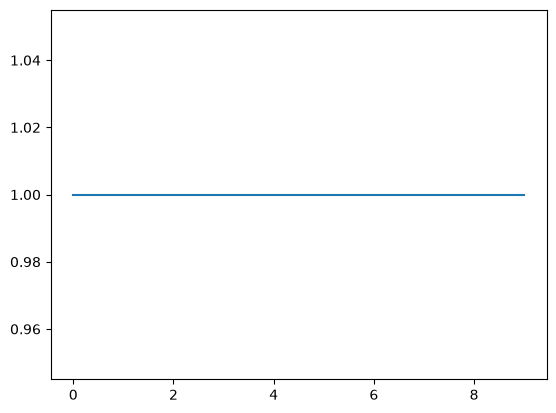

In [ ]:
from typing import Callable, TypeVar
import matplotlib.pyplot as plt
T = TypeVar('T')
class Seq[T]:
    f : Callable[[int], T]

    def __init__(self, f: Callable[[int], T]):
        self.f = f
    @staticmethod
    def const(value: T) -> 'Seq[T]':
        return Seq(lambda n: value)
    def __call__(self, n: int) -> T:
        return self.f(n)
    def __add__(self, other: 'Seq[T]') -> 'Seq[T]':
        return Seq(lambda n: self(n) + other(n))
    def __sub__(self, other: 'Seq[T]') -> 'Seq[T]':
        return Seq(lambda n: self(n) - other(n))
    def __mul__(self, other: 'Seq[T]') -> 'Seq[T]':
        return Seq(lambda n: self(n) * other(n))
    def __truediv__(self, other: 'Seq[T]') -> 'Seq[T]':
        return Seq(lambda n: self(n) / other(n))
    def eq1(self, other: 'Seq[T]') -> 'Seq[bool]':
        return Seq(lambda n: self(n) == other(n))
    #def eq2(self, other: 'Seq[T]') :    
    #    return Seq(lambda n: np.norm(self(n) - other(n)))
    def dist(self, other: 'Seq[T]') -> 'Seq[float]':
        return Seq(lambda n: np.linalg.norm(self(n) - other(n)))
    def plot(self, N: int):

        plt.plot([self(n) for n in range(N)])
        plt.show()

N = Seq(lambda n: n)
normN = lambda v: norm(v) / N




Different norms have different asymptotic behavior and hence different implied equivalence classes x-y --> 0
1/N
1/N**2
subspaces


In [ ]:
def proj(T, lo, hi):
    def res(N):
        u, s, vh = np.linalg.svd(T(N))
        s = np.clip(s, lo(N), hi(N))
        return u @ np.diag(s) @ vh
    return res




# interpolation and decimation. Could move down or up by 1 or factor of 2
# How to do it depends on our interpreation. Are we sampling points? Enumerating fourier coefficients? something else.
# chebfun
def interp(v):
    def res(N):
        u = v[N]
        return (u[::2] + u[1::2]) / 2
def dec(v):


In [ ]:
import numpy as np
np.norm(np.ones(3))




array([1., 1., 1.])